# Financial News Sentiment: Where Does a Simple Model Go Wrong?

INST414 Module 5 assignment. Hein Linn Htet.

The question: Can a cheap, easy-to-explain model sort financial news headlines into positive, negative, and neutral well enough to automate the job, and what kinds of headlines does it get wrong?

The stakeholder: A product manager at a financial news alert service for retail investors. The service has to sort thousands of news headlines every day, and reading all of them by hand is slow and expensive.

The decisions this answer informs:
1. Whether to use the simple model at all.
2. How confident the model must be before a headline is labeled automatically. Anything below that confidence goes to a human reviewer.
3. Which kinds of headlines should always go to a human.

The data: "Sentiment Analysis for Financial News" on Kaggle: https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news. It is the Financial PhraseBank (Malo et al., 2014) in one CSV file, all-data.csv. It has 4,846 English news headlines and sentences and two columns: Sentiment and News Headline.

License: Kaggle lists the license as CC BY-NC-SA 4.0. The original release (the dataset card on Hugging Face, https://huggingface.co/datasets/takala/financial_phrasebank) lists CC BY-NC-SA 3.0. Both versions allow non-commercial use only.

How the ground-truth labels were made: the original authors had 16 annotators with a background in finance (3 researchers and 13 master's students at Aalto University School of Business). Each sentence was labeled positive, negative, or neutral by 5 to 8 of them, from an investor's point of view, and the final label is the majority vote. This file keeps every sentence where at least half of the annotators agreed, so some labels rest on a fairly weak consensus.

What this notebook does, in order:
1. Load the CSV.
2. Check and clean the text.
3. Remove duplicates.
4. Split into training and test sets.
5. Train two baselines and the main model (TF-IDF + Logistic Regression) with grid search.
6. Evaluate on the test set.
7. Analyze the errors and look closely at 5 of them.
8. Answer the question.

How to run this notebook: install the packages in requirements.txt (pip install -r requirements.txt). Download all-data.csv from the Kaggle link above and put it in a folder called data next to this notebook. Then run all cells from top to bottom. The whole notebook runs in about a minute on a laptop.

## 1. Setup

This cell loads the libraries, creates folders for figures and results, and sets a fixed random seed.

Why the fixed seed: the train/test split and cross-validation folds use randomness. Fixing the seed means I get the same split every time, so my numbers and my 5 error examples stay the same and anyone can reproduce them.

I also set one chart style here so every figure looks the same. The three classes always use the same colors: red for negative, gray for neutral, blue for positive.

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)

SEED = 42
DATA_PATH = Path("data") / "all-data.csv"
FIG_DIR = Path("figures")
RESULTS_DIR = Path("results")
for folder in [DATA_PATH.parent, FIG_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ["negative", "neutral", "positive"]
CLASS_COLORS = {"negative": "#e34948", "neutral": "#8f8e88", "positive": "#2a78d6"}
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_SOFT = "#0b0b0b", "#52514e"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#f5f9fe", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_SOFT, "text.color": INK,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def save_fig(fig, name):
    """Save a figure as a PNG in the figures folder so I can use it in the Medium post."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    print(f"Saved {path}")

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.5 | scikit-learn 1.9.1


## 2. Load the data

The file all-data.csv comes from Kaggle. If it is not in the data folder yet, this cell tries to download it with the kagglehub library. If that fails (for example because you are not logged in to Kaggle), download the file by hand from the link at the top and put it in the data folder.

Three things about this file cause common bugs, so I handle them here:
1. It has no header row. The first line is already data. If you read it with the default settings, pandas uses the first headline as the column names and you silently lose one row. So I set header=None and give the column names myself.
2. It is not saved as UTF-8. It uses an older encoding called Latin-1. Reading it with the default UTF-8 setting crashes with a UnicodeDecodeError, so I set encoding="latin-1".
3. Lines end with an old Mac-style line break. pandas handles this fine, but some other tools (for example counting lines in a terminal) report the wrong number of rows.

In [2]:
if not DATA_PATH.exists():
    try:
        import kagglehub, shutil
        folder = Path(kagglehub.dataset_download("ankurzing/sentiment-analysis-for-financial-news"))
        shutil.copy(folder / "all-data.csv", DATA_PATH)
        print(f"Downloaded with kagglehub to {DATA_PATH}")
    except Exception as error:
        raise FileNotFoundError(
            "Could not download all-data.csv. Download it from "
            "https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news "
            f"and save it as {DATA_PATH}. Error: {error}")

raw = pd.read_csv(DATA_PATH, header=None, names=["sentiment", "headline"], encoding="latin-1")
print(f"Loaded {len(raw)} rows and {raw.shape[1]} columns")
raw.head()

Loaded 4846 rows and 2 columns


,sentiment,headline
0,neutral,"According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing ."
1,neutral,"Technopolis plans to develop in stages an area of no less than 100,000 square meters in order to host companies working in computer technologies and telecommunications , the statement said ."
2,negative,The international electronic industry company Elcoteq has laid off tens of employees from its Tallinn facility ; contrary to earlier layoffs the company contracted the ranks of its office workers ...
3,positive,With the new production plant the company would increase its capacity to meet the expected increase in demand and would improve the use of raw materials and therefore increase the production profi...
4,positive,"According to the company 's updated strategy for the years 2009-2012 , Basware targets a long-term net sales growth in the range of 20 % -40 % with an operating profit margin of 10 % -20 % of net ..."


Before going further I check the data against what the dataset should contain: 4,846 rows, with 2,879 neutral, 1,363 positive, and 604 negative. I also check for missing values.

Why: if I had loaded the file wrong (for example, lost the first row to a header), these numbers would not match, and I would find out now instead of after training a model on broken data.

In [3]:
assert len(raw) == 4846, f"Expected 4846 rows, got {len(raw)}"
assert raw.isna().sum().sum() == 0, "There are missing values"
assert raw["sentiment"].value_counts().to_dict() == {"neutral": 2879, "positive": 1363, "negative": 604}
print("Row count, label counts, and missing values all check out.")
raw["sentiment"].value_counts().to_frame("rows")

Row count, label counts, and missing values all check out.


,rows
sentiment,
neutral,2879
positive,1363
negative,604


## 3. Clean the text

Here is what I clean and why.

Broken characters. Some company and place names have encoding damage. For example the company name Seppälä appears as something like "Sepp+Æl+Æ". These broken characters only appear inside names. They carry no sentiment, so I remove all non-ASCII characters.

Extra spaces. I trim spaces at the start and end and turn runs of spaces into a single space.

Labels. I make labels lowercase with no spaces and check that only negative, neutral, and positive appear.

Empty rows. I drop any headline that ends up empty.

What I do not clean: the text is already split into tokens with spaces around punctuation (for example "company 's" and "EUR 5.2 mn ."). I leave that alone because the TF-IDF tokenizer ignores punctuation anyway. I also keep numbers and words like not, up, and down, because they matter for financial sentiment.

First, a look at the broken characters:

In [4]:
has_non_ascii = raw["headline"].str.contains(r"[^\x00-\x7F]", regex=True)
print(f"Headlines with non-ASCII characters: {has_non_ascii.sum()} of {len(raw)}")
raw.loc[has_non_ascii, "headline"].head(3).to_list()

Headlines with non-ASCII characters: 84 of 4846


["Clothing retail chain Sepp+Æl+Æ 's sales increased by 8 % to EUR 155.2 mn , and operating profit rose to EUR 31.1 mn from EUR 17.1 mn in 2004 .",
 "Net sales of Finnish food industry company L+Ænnen Tehtaat 's continuing operations increased by 13 % in 2008 to EUR 349.1 mn from EUR 309.6 mn in 2007 .",
 "Clothing chain Sepp+Æl+Æ 's net sales increased by 7.0 % to EUR 30.8 mn ."]

Now the cleaning itself.

In [5]:
def clean_text(text):
    text = re.sub(r"[^\x00-\x7F]+", "", text)   # remove broken non-ASCII characters
    text = re.sub(r"\s+", " ", text)            # turn runs of spaces into one space
    return text.strip()

df = raw.copy()
df["headline"] = df["headline"].map(clean_text)
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df = df[df["headline"].str.len() > 0].reset_index(drop=True)

assert set(df["sentiment"]) == set(CLASSES)
assert not df["headline"].str.contains(r"[^\x00-\x7F]", regex=True).any()
print(f"{len(raw)} rows before cleaning, {len(df)} after")

4846 rows before cleaning, 4846 after


## 4. Remove duplicates

Some headlines appear more than once.

Why this matters: if the same headline ends up in both the training set and the test set, the model has already seen the answer during training. That makes the test score look better than it really is. This is called data leakage, so duplicates must be removed before splitting.

How I compare headlines: I compare lowercase versions, so "Profit rose" and "profit rose" count as the same headline.

What I do with duplicates:
1. If the copies have the same label, I keep one copy.
2. If the copies have different labels, the ground truth contradicts itself, so I drop every copy. A headline cannot be both positive and neutral.

In [6]:
df["key"] = df["headline"].str.lower()
labels_per_key = df.groupby("key")["sentiment"].nunique()
conflict_keys = set(labels_per_key[labels_per_key > 1].index)
conflicts = df[df["key"].isin(conflict_keys)]

df = df[~df["key"].isin(conflict_keys)]
n_before = len(df)
df = df.drop_duplicates(subset="key", keep="first").drop(columns="key").reset_index(drop=True)

print(f"Dropped {len(conflicts)} rows with conflicting labels and {n_before - len(df)} extra copies.")
print(f"Final dataset: {len(df)} headlines")
conflicts[["headline", "sentiment"]]

Dropped 4 rows with conflicting labels and 6 extra copies.
Final dataset: 4836 headlines


,headline,sentiment
78,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sells stake in Morning Digital Design Oy Finnish IT company TJ Group Plc said on Friday 7 April that it had signed an agreement on selling its shares of ...,neutral
79,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sells stake in Morning Digital Design Oy Finnish IT company TJ Group Plc said on Friday 7 April that it had signed an agreement on selling its shares of ...,positive
788,The Group 's business is balanced by its broad portfolio of sports and presence in all major markets .,positive
789,The Group 's business is balanced by its broad portfolio of sports and presence in all major markets .,neutral


The class balance of the final dataset. Neutral is by far the biggest class. That means a model can get a high accuracy just by guessing neutral every time, so accuracy alone is not a good way to judge the model.

Saved figures/01_class_balance.png


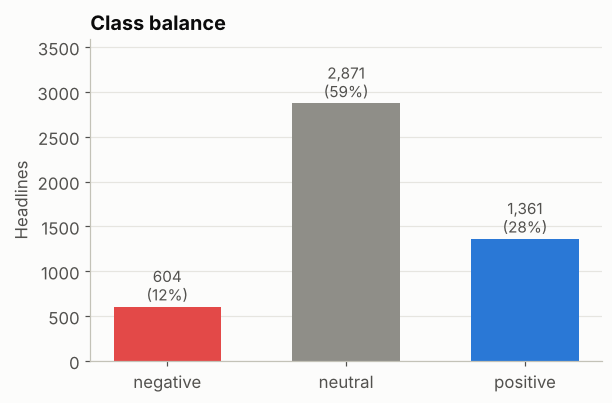

In [7]:
counts = df["sentiment"].value_counts().reindex(CLASSES)

fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(CLASSES, counts.values, color=[CLASS_COLORS[c] for c in CLASSES], width=0.6)
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 30,
            f"{value:,}\n({value / len(df):.0%})", ha="center", va="bottom", fontsize=10, color=INK_SOFT)
ax.set_title("Class balance")
ax.set_ylabel("Headlines")
ax.set_ylim(0, counts.max() * 1.25)
ax.grid(axis="x", visible=False)
save_fig(fig, "01_class_balance")
plt.show()

## 5. Split into training and test sets

I split the data into 80% training and 20% test.

Why stratified: stratifying keeps the same share of negative, neutral, and positive headlines in both sets. Without it, the small negative class could end up underrepresented in the test set by chance.

Why the test set stays untouched: I make all model choices (which model, which settings) using only the training set and cross-validation. I look at the test set once, at the end. If I tuned the model while watching the test score, the test score would no longer be an honest estimate of how the model does on new headlines.

The checks at the end confirm that no headline is in both sets.

In [8]:
train_df, test_df = train_test_split(df, test_size=0.20, stratify=df["sentiment"], random_state=SEED)
X_train, y_train = train_df["headline"], train_df["sentiment"]
X_test, y_test = test_df["headline"], test_df["sentiment"]

assert not set(X_train.str.lower()) & set(X_test.str.lower()), "A headline is in both train and test"
assert len(train_df) + len(test_df) == len(df)

print(f"Training headlines: {len(train_df)} | Test headlines: {len(test_df)}")
pd.DataFrame({"train": y_train.value_counts(normalize=True).reindex(CLASSES),
              "test": y_test.value_counts(normalize=True).reindex(CLASSES)}).map("{:.1%}".format)

Training headlines: 3868 | Test headlines: 968


,train,test
sentiment,,
negative,12.5%,12.5%
neutral,59.4%,59.4%
positive,28.2%,28.1%


## 6. Features: TF-IDF

The model cannot read text, so I turn each headline into numbers with TF-IDF. TF-IDF gives each word a score that is high when the word appears in this headline but is not common across all headlines. Words like "the" get low scores and words like "profit" or "decreased" get higher scores.

My settings and why:
1. Single words and two-word phrases (ngram_range 1 to 2). Phrases like "rose to", "fell from", and "not expected" carry direction that single words miss. Grid search checks whether this actually helps.
2. Lowercase everything, so "Profit" and "profit" are the same feature.
3. Ignore words that appear in only one training headline (min_df=2). They are usually names or typos and just add noise.
4. Sublinear term frequency, so a word repeated three times does not count three times as much.
5. No stopword removal. This is important, and the cell below shows why.

In [9]:
sentiment_words = ["not", "no", "never", "nor", "up", "down", "above", "below",
                   "less", "more", "against", "few", "over", "under"]
print("Words scikit-learn's built-in English stopword list would remove:")
print([w for w in sentiment_words if w in ENGLISH_STOP_WORDS])

def make_tfidf():
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2,
                           sublinear_tf=True, stop_words=None)

Words scikit-learn's built-in English stopword list would remove:
['not', 'no', 'never', 'nor', 'up', 'down', 'above', 'below', 'less', 'more', 'against', 'few', 'over', 'under']


These words decide the meaning of many financial headlines ("profit was not up", "sales were down"). If I had used stop_words="english", the model would never see them. This is an easy bug to make, because removing stopwords is a common default step in text tutorials.

## 7. Baselines

A baseline is a simple model that sets the bar. If my main model cannot beat it, the main model is not useful.

Baseline 1, majority class: always predict the most common class (neutral). This shows how good a model can look while learning nothing.

Baseline 2, Multinomial Naive Bayes: a classic, fast model for word counts. It uses the same TF-IDF features as the main model, so the comparison is fair. I tune its one setting (alpha, the amount of smoothing) with grid search.

How I score models: 5-fold stratified cross-validation on the training set only. The training set is split into 5 parts, and each part takes a turn as a mini test set while the model trains on the other 4. The main score is macro F1, which is the average F1 across the three classes. It treats the small negative class as just as important as neutral, so a model cannot hide a bad negative score behind a good neutral score.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

majority_grid = GridSearchCV(DummyClassifier(strategy="most_frequent"), param_grid={}, cv=cv, scoring="f1_macro")
majority_grid.fit(X_train, y_train)

nb_pipeline = Pipeline([("tfidf", make_tfidf()), ("clf", MultinomialNB())])
nb_grid = GridSearchCV(nb_pipeline, param_grid={"clf__alpha": [0.01, 0.03, 0.1, 0.3, 1.0]},
                       cv=cv, scoring="f1_macro", n_jobs=-1)
nb_grid.fit(X_train, y_train)

print(f"Majority class  | cross-validated macro F1: {majority_grid.best_score_:.3f}")
print(f"Naive Bayes     | cross-validated macro F1: {nb_grid.best_score_:.3f} | best alpha: {nb_grid.best_params_['clf__alpha']}")

Majority class  | cross-validated macro F1: 0.248
Naive Bayes     | cross-validated macro F1: 0.669 | best alpha: 0.1


## 8. Main model: Logistic Regression with grid search

Why this is a classification problem: the target, sentiment, is categorical with three values (negative, neutral, positive). It is not a number on a scale. The stakeholder also needs a label to route each headline. So I use a classification model, not regression.

Why Logistic Regression:
1. It works well on TF-IDF features with only a few thousand headlines.
2. It is easy to explain. Each word gets one weight per class, so for any prediction I can see which words pushed it toward which class. That is exactly what I need for the error analysis.
3. It gives a probability for each class. I use those probabilities to decide when the model is confident enough to label a headline on its own.

Why a pipeline: the pipeline joins TF-IDF and the model into one object. During cross-validation, the vectorizer is re-fitted on the training folds only, every time, so the vocabulary never includes words from the fold being scored. No information leaks.

Why class_weight="balanced": negative is only about 12% of the data. Balanced weights make mistakes on rare classes cost more during training, so the model does not just favor neutral.

What grid search tries:
1. C, how strongly the model is held back from overfitting. Small C means simpler weights. Large C lets the model fit the training data more closely.
2. Single words only, versus single words plus two-word phrases.

That is 12 combinations, each tested with 5-fold cross-validation. The best one is chosen by macro F1.

In [11]:
lr_pipeline = Pipeline([
    ("tfidf", make_tfidf()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)),
])
lr_param_grid = {"clf__C": [0.3, 1, 3, 10, 30, 100], "tfidf__ngram_range": [(1, 1), (1, 2)]}
lr_grid = GridSearchCV(lr_pipeline, lr_param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
lr_grid.fit(X_train, y_train)

cv_table = (pd.DataFrame(lr_grid.cv_results_)
            .assign(C=lambda d: d["param_clf__C"], ngrams=lambda d: d["param_tfidf__ngram_range"].astype(str))
            [["C", "ngrams", "mean_test_score", "std_test_score", "rank_test_score"]]
            .rename(columns={"mean_test_score": "cv_macro_f1", "std_test_score": "cv_std", "rank_test_score": "rank"})
            .sort_values("rank").round(3))
print("Best settings:", lr_grid.best_params_)
print(f"Best cross-validated macro F1: {lr_grid.best_score_:.3f}")
cv_table.head(6)

Best settings: {'clf__C': 3, 'tfidf__ngram_range': (1, 2)}
Best cross-validated macro F1: 0.729


,C,ngrams,cv_macro_f1,cv_std,rank
5,3.0,"(1, 2)",0.729,0.013,1
7,10.0,"(1, 2)",0.727,0.015,2
9,30.0,"(1, 2)",0.725,0.014,3
11,100.0,"(1, 2)",0.725,0.012,4
3,1.0,"(1, 2)",0.717,0.014,5
4,3.0,"(1, 1)",0.717,0.017,6


## 9. Evaluate on the test set

Now, and only now, I use the test set.

For each of the three models I report:
1. Accuracy: the share of headlines labeled correctly.
2. Macro F1: my main metric, because of the class imbalance.
3. F1 for each class separately, to see which classes are hard.

I also put the cross-validated macro F1 next to the test macro F1. If the two are close, the cross-validation estimate was honest and the model is not overfitted to the training data.

In [12]:
models = {"Majority class": majority_grid, "Naive Bayes": nb_grid, "Logistic Regression": lr_grid}
rows = []
for name, grid in models.items():
    pred = grid.best_estimator_.predict(X_test)
    per_class_f1 = f1_score(y_test, pred, labels=CLASSES, average=None, zero_division=0)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "macro F1 (test)": f1_score(y_test, pred, average="macro", zero_division=0),
                 "macro F1 (cv)": grid.best_score_,
                 **{f"F1 {c}": v for c, v in zip(CLASSES, per_class_f1)}})
comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison.to_csv(RESULTS_DIR / "model_comparison.csv")
comparison

,accuracy,macro F1 (test),macro F1 (cv),F1 negative,F1 neutral,F1 positive
model,,,,,,
Majority class,0.594,0.248,0.248,0.000,0.745,0.000
Naive Bayes,0.740,0.667,0.669,0.602,0.823,0.577
Logistic Regression,0.776,0.731,0.729,0.661,0.836,0.697


The full report for Logistic Regression. Precision answers: when the model says "negative", how often is it right? Recall answers: of all the truly negative headlines, how many did the model find? Support is the number of test headlines in each class.

In [13]:
best_model = lr_grid.best_estimator_
test_pred = best_model.predict(X_test)
test_proba = best_model.predict_proba(X_test)
print(classification_report(y_test, test_pred, labels=CLASSES, digits=3))

              precision    recall  f1-score   support

    negative      0.653     0.669     0.661       121
     neutral      0.827     0.845     0.836       575
    positive      0.719     0.676     0.697       272

    accuracy                          0.776       968
   macro avg      0.733     0.730     0.731       968
weighted avg      0.775     0.776     0.775       968



The confusion matrix shows exactly which mistakes the model makes. Rows are the true labels and columns are the model's predictions. The diagonal is correct predictions. Each cell shows the count and the share of that row.

Saved figures/02_confusion_matrix.png


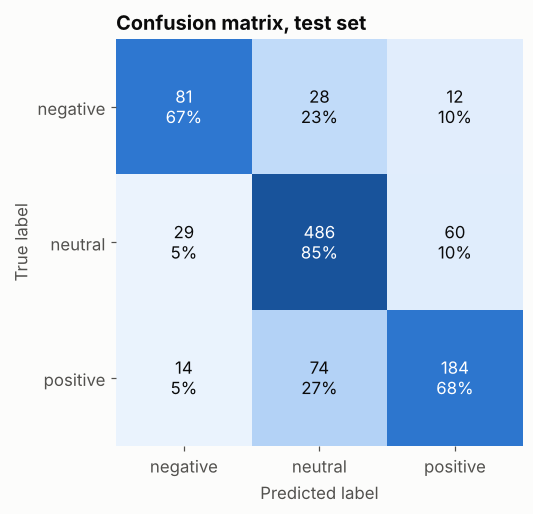

In [14]:
cm = confusion_matrix(y_test, test_pred, labels=CLASSES)
row_share = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(5.6, 4.8))
ax.imshow(row_share, cmap=BLUES, vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        color = "white" if row_share[i, j] > 0.55 else INK
        ax.text(j, i, f"{cm[i, j]}\n{row_share[i, j]:.0%}", ha="center", va="center", color=color, fontsize=11)
ax.set_xticks(range(3), CLASSES)
ax.set_yticks(range(3), CLASSES)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion matrix, test set")
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
save_fig(fig, "02_confusion_matrix")
plt.show()

A sanity check on what the model learned: the words and phrases with the largest weights for each class. If the model learned sensible things, positive should show words like "increased" and "rose", and negative should show words like "decreased" and "fell". If I saw names or random words at the top, it would mean the model learned something odd.

Saved figures/03_top_terms.png


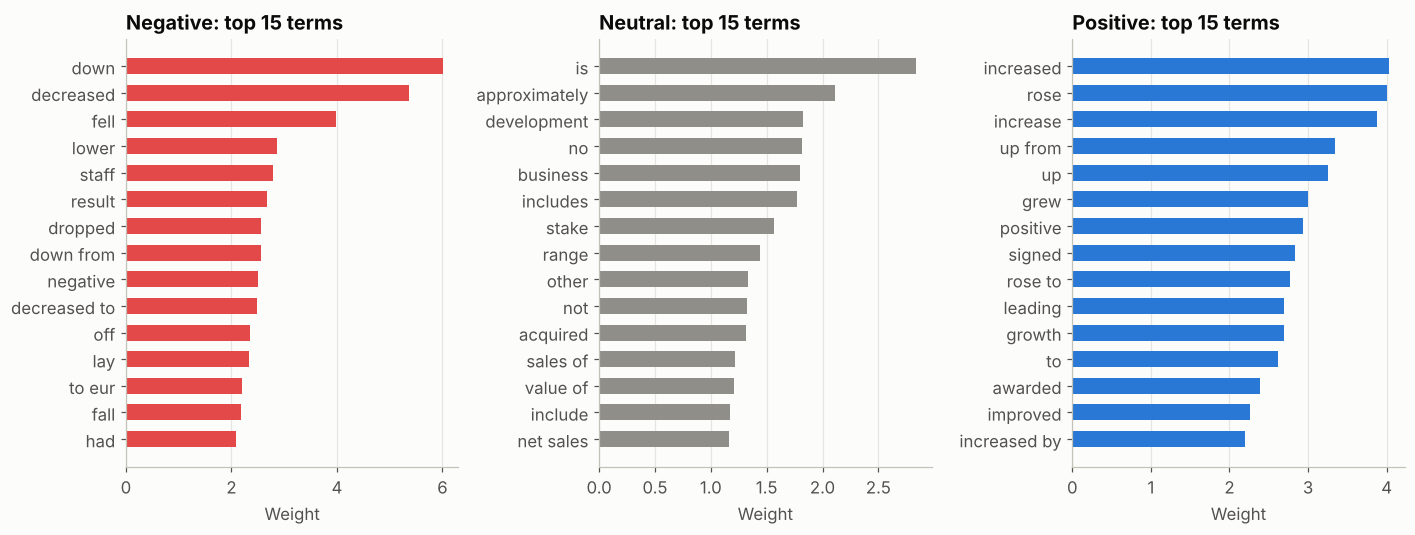

In [15]:
vectorizer = best_model.named_steps["tfidf"]
classifier = best_model.named_steps["clf"]
feature_names = vectorizer.get_feature_names_out()
class_index = {c: i for i, c in enumerate(classifier.classes_)}

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, cls in zip(axes, CLASSES):
    weights = classifier.coef_[class_index[cls]]
    top = np.argsort(weights)[-15:]
    ax.barh(feature_names[top], weights[top], color=CLASS_COLORS[cls], height=0.6)
    ax.set_title(f"{cls.capitalize()}: top 15 terms")
    ax.set_xlabel("Weight")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "03_top_terms")
plt.show()

How confident is the model when it is right versus when it is wrong? Confidence here is the probability the model gives to the class it picked.

If wrong answers mostly come with low confidence, then confidence is a useful signal for sending headlines to a human reviewer.

Saved figures/04_confidence_right_vs_wrong.png


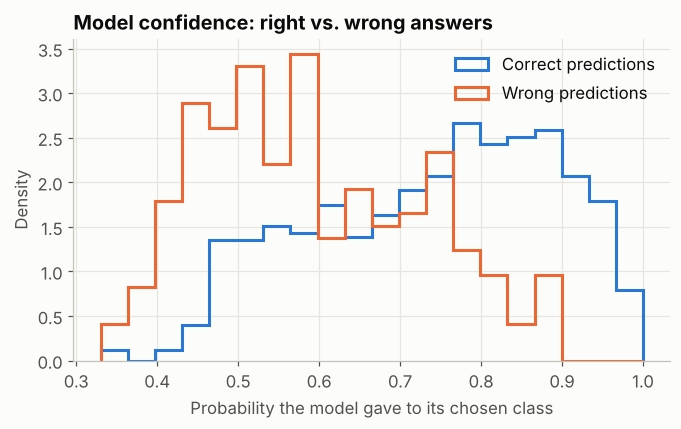

Median confidence when correct: 0.77
Median confidence when wrong:   0.57


In [16]:
test_results = test_df.copy()
test_results["pred"] = test_pred
test_results["confidence"] = test_proba.max(axis=1)
test_results["correct"] = test_results["pred"] == test_results["sentiment"]

fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.linspace(0.33, 1.0, 21)
ax.hist(test_results.loc[test_results["correct"], "confidence"], bins=bins, density=True,
        histtype="step", linewidth=2, color=BLUE, label="Correct predictions")
ax.hist(test_results.loc[~test_results["correct"], "confidence"], bins=bins, density=True,
        histtype="step", linewidth=2, color=ORANGE, label="Wrong predictions")
ax.set_title("Model confidence: right vs. wrong answers")
ax.set_xlabel("Probability the model gave to its chosen class")
ax.set_ylabel("Density")
ax.legend(frameon=False)
save_fig(fig, "04_confidence_right_vs_wrong")
plt.show()

print(f"Median confidence when correct: {test_results.loc[test_results['correct'], 'confidence'].median():.2f}")
print(f"Median confidence when wrong:   {test_results.loc[~test_results['correct'], 'confidence'].median():.2f}")

This is the analysis that answers the stakeholder's decision. If the model only labels headlines where its confidence is above some threshold and sends the rest to a person, two things trade off:

1. Coverage: the share of headlines the model labels on its own.
2. Accuracy on those headlines.

A higher threshold means fewer headlines are labeled automatically, but those are labeled more accurately.

How I pick the threshold without cheating: I pick it using the training set only, with cross-validated predictions (every training headline gets a prediction from a model that did not see it). I choose the lowest threshold where those predictions reach 90% accuracy. Then I check that threshold once on the test set.

Saved figures/05_coverage_vs_accuracy.png


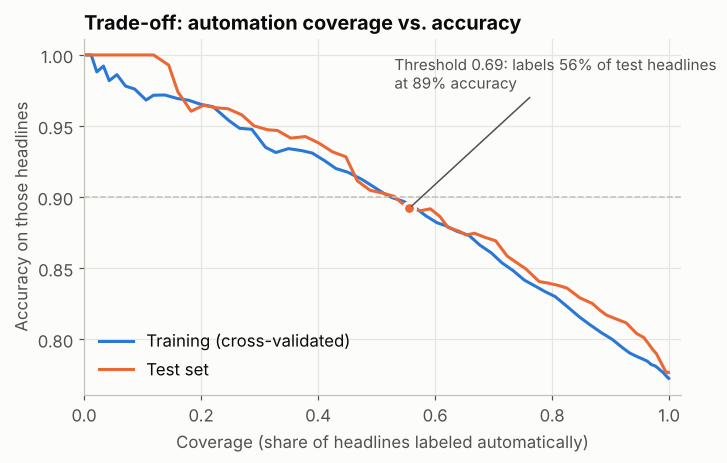

Chosen threshold (from training data): 0.69
Training, cross-validated: coverage 51.2%, accuracy 90.3%
Test set:                  coverage 55.6%, accuracy 89.2%
Overall test accuracy without a threshold: 77.6%


In [17]:
TARGET_ACCURACY = 0.90

train_oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)
train_oof_pred = np.array(best_model.classes_)[train_oof_proba.argmax(axis=1)]
train_oof_conf = train_oof_proba.max(axis=1)
train_oof_correct = train_oof_pred == y_train.to_numpy()

def coverage_curve(confidence, correct, thresholds):
    rows = []
    for t in thresholds:
        kept = confidence >= t
        rows.append({"threshold": t, "coverage": kept.mean(),
                     "accuracy": correct[kept].mean() if kept.any() else np.nan})
    return pd.DataFrame(rows)

thresholds = np.round(np.arange(0.34, 0.99, 0.01), 2)
train_curve = coverage_curve(train_oof_conf, train_oof_correct, thresholds)
test_curve = coverage_curve(test_results["confidence"].to_numpy(), test_results["correct"].to_numpy(), thresholds)

chosen_threshold = train_curve.loc[train_curve["accuracy"] >= TARGET_ACCURACY, "threshold"].min()
train_at = train_curve.set_index("threshold").loc[chosen_threshold]
test_at = test_curve.set_index("threshold").loc[chosen_threshold]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(train_curve["coverage"], train_curve["accuracy"], color=BLUE, linewidth=2, label="Training (cross-validated)")
ax.plot(test_curve["coverage"], test_curve["accuracy"], color=ORANGE, linewidth=2, label="Test set")
ax.scatter([test_at["coverage"]], [test_at["accuracy"]], s=60, color=ORANGE, zorder=3, edgecolor="#fcfcfb", linewidth=2)
ax.annotate(f"Threshold {chosen_threshold:.2f}: labels {test_at['coverage']:.0%} of test headlines\n"
            f"at {test_at['accuracy']:.0%} accuracy",
            xy=(test_at["coverage"], test_at["accuracy"]), xytext=(0.52, 0.86),
            textcoords="axes fraction", fontsize=10, color=INK_SOFT,
            arrowprops=dict(arrowstyle="-", color=INK_SOFT, linewidth=1))
ax.axhline(TARGET_ACCURACY, color="#c3c2b7", linewidth=1, linestyle="--")
ax.set_xlabel("Coverage (share of headlines labeled automatically)")
ax.set_ylabel("Accuracy on those headlines")
ax.set_title("Trade-off: automation coverage vs. accuracy")
ax.set_xlim(0, 1.02)
ax.legend(frameon=False, loc="lower left")
save_fig(fig, "05_coverage_vs_accuracy")
plt.show()

print(f"Chosen threshold (from training data): {chosen_threshold:.2f}")
print(f"Training, cross-validated: coverage {train_at['coverage']:.1%}, accuracy {train_at['accuracy']:.1%}")
print(f"Test set:                  coverage {test_at['coverage']:.1%}, accuracy {test_at['accuracy']:.1%}")
print(f"Overall test accuracy without a threshold: {test_results['correct'].mean():.1%}")

## 10. Error analysis

This is the main part of the project. My plan:

1. Build a table of every test headline the model got wrong.
2. Count which kinds of mix-ups happen (for example, positive predicted as neutral).
3. Tag each error with simple rules that describe what kind of headline it is.
4. Pick 5 confident errors of different kinds.
5. For each one, show which words pushed the model to the wrong answer, then run a sensitivity check by removing those words and predicting again.

First, three helper functions.

word_pushes shows how much each word or phrase pushed the model toward the wrong class instead of the true class. For each term, it takes the term's TF-IDF score times the difference between its weight for the predicted class and its weight for the true class. A positive number means the term pulled the model toward the wrong answer. A negative number means it pulled toward the right answer, just not strongly enough.

unfamiliar_words lists the lowercase words that the model never learned. They are not in its vocabulary, usually because they appeared in fewer than 2 training headlines. To the model, these words do not exist. I only count lowercase words so that company and place names are skipped.

remove_words_test is a sensitivity check. It deletes the 3 words that pushed hardest toward the wrong answer and asks the model again. If the prediction flips to the right answer, that supports the idea that misleading words drove the error. If it does not flip, the problem is more likely missing evidence: nothing in the headline points the model to the right answer. This is not proof of the cause, because deleting words also changes the sentence and the TF-IDF weights of the remaining words.

In [18]:
def word_pushes(text, true_label, pred_label):
    x = vectorizer.transform([text])
    diff = classifier.coef_[class_index[pred_label]] - classifier.coef_[class_index[true_label]]
    table = pd.DataFrame({"term": feature_names[x.indices], "push": x.data * diff[x.indices]})
    return table.sort_values("push", ascending=False).reset_index(drop=True)

vocabulary = vectorizer.vocabulary_
def unfamiliar_words(text):
    return sorted({w for w in re.findall(r"\b[a-z]{4,}\b", text) if w not in vocabulary})

def remove_words_test(text, true_label, pred_label, n_words=3):
    pushes = word_pushes(text, true_label, pred_label)
    single = pushes[(~pushes["term"].str.contains(" ")) & (pushes["push"] > 0)].head(n_words)
    edited = text
    for word in single["term"]:
        edited = re.sub(rf"\b{re.escape(word)}\b", "", edited, flags=re.IGNORECASE)
    edited = re.sub(r"\s+", " ", edited).strip()
    i_true = list(best_model.classes_).index(true_label)
    before = best_model.predict_proba([text])[0]
    after = best_model.predict_proba([edited])[0]
    return {"removed": list(single["term"]),
            "new prediction": str(best_model.classes_[after.argmax()]),
            f"P({true_label}) before": round(float(before[i_true]), 3),
            f"P({true_label}) after": round(float(after[i_true]), 3)}

errors = test_results[~test_results["correct"]].copy()
wrong_rows = ~test_results["correct"].to_numpy()
for cls in CLASSES:
    errors[f"P({cls})"] = test_proba[wrong_rows][:, list(best_model.classes_).index(cls)].round(3)
errors["mix-up"] = errors["sentiment"] + " -> " + errors["pred"]
print(f"The model got {len(errors)} of {len(test_results)} test headlines wrong ({len(errors) / len(test_results):.1%}).")

The model got 217 of 968 test headlines wrong (22.4%).


Which mix-ups happen most? The arrow reads "true label -> predicted label".

In [19]:
mixups = (errors.groupby("mix-up")
          .agg(count=("headline", "size"), median_confidence=("confidence", "median"))
          .sort_values("count", ascending=False))
mixups["share of errors"] = (mixups["count"] / len(errors)).map("{:.0%}".format)
mixups.round(2)

,count,median_confidence,share of errors
mix-up,,,
positive -> neutral,74,0.60,34%
neutral -> positive,60,0.57,28%
neutral -> negative,29,0.51,13%
negative -> neutral,28,0.64,13%
positive -> negative,14,0.50,6%
negative -> positive,12,0.52,6%


Next I tag each error with simple rules. A headline can get more than one tag. These rules are a rough first pass to help sort the errors, not a perfect classifier. They have not been checked by hand for all 217 errors. The 5 errors I study closely below are the ones I read and checked myself.

The tags:
1. Compares amounts: at least two money or percent amounts and a word like "from", "compared", or "versus" (for example "profit rose to EUR 13.1 mn from EUR 8.7 mn"). TF-IDF cannot compare numbers, so I expected these to be hard.
2. Loss or cost going up or down: a bad thing (loss, cost, debt, expenses) together with a direction word (increase, decrease, narrow, fall, and so on). "Loss narrowed" is good news even though both words look negative, and "costs increased" is bad news even though "increased" usually means good news.
3. Contrast or negation: words like not, no, despite, although, but, however, or while, which can flip or mix the meaning.
4. Has unfamiliar word: a lowercase word the model never learned.
5. No tag: none of the rules apply.

To see whether a tag really explains errors, I compare how common it is among errors versus among correct predictions. A tag that is much more common among errors points to a real weak spot. If the shares are about the same, the tag does not explain the errors.

Saved figures/06_error_tags.png


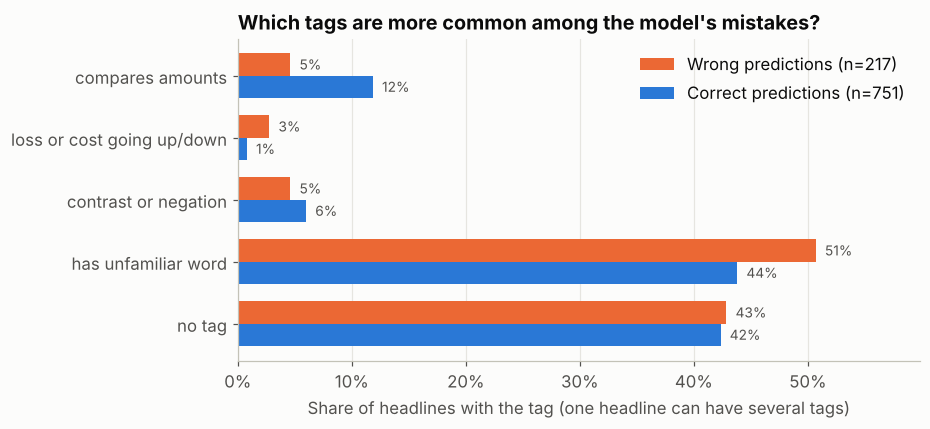

,errors,correct
compares amounts,5%,12%
loss or cost going up/down,3%,1%
contrast or negation,5%,6%
has unfamiliar word,51%,44%
no tag,43%,42%


In [20]:
AMOUNT = r"(\d+(?:[.,]\d+)?\s*(%|mn|million|bn|billion|m\b)|\b(eur|usd|sek|gbp)\s*\d)"
COMPARE_WORDS = r"\b(from|compared|versus|vs|against|year-on-year|corresponding)\b"
BAD_THINGS = r"\b(loss|losses|cost|costs|debt|expenses|expenditure|liabilities|impairment|write-?downs?)\b"
DIRECTION_WORDS = (r"\b(increas\w*|decreas\w*|rose|rise|rising|grew|grow\w*|fell|fall\w*|declin\w*|drop\w*|"
                   r"narrow\w*|widen\w*|reduc\w*|cut|cuts|lower|higher|down|up|improv\w*|doubl\w*)\b")
CONTRAST_WORDS = r"(\bnot\b|\bno\b|\bnever\b|n't\b|\bdespite\b|\balthough\b|\bthough\b|\bhowever\b|\bbut\b|\bwhile\b|\bwhereas\b)"
TAG_ORDER = ["compares amounts", "loss or cost going up/down", "contrast or negation", "has unfamiliar word", "no tag"]

def tag_headline(text):
    s = text.lower()
    tags = []
    if len(re.findall(AMOUNT, s)) >= 2 and re.search(COMPARE_WORDS, s):
        tags.append("compares amounts")
    if re.search(BAD_THINGS, s) and re.search(DIRECTION_WORDS, s):
        tags.append("loss or cost going up/down")
    if re.search(CONTRAST_WORDS, s):
        tags.append("contrast or negation")
    if unfamiliar_words(text):
        tags.append("has unfamiliar word")
    return tags or ["no tag"]

errors["tags"] = errors["headline"].map(tag_headline)
correct_rows = test_results[test_results["correct"]]
tag_shares = pd.DataFrame({
    "errors": errors["tags"].explode().value_counts().reindex(TAG_ORDER).fillna(0) / len(errors),
    "correct": correct_rows["headline"].map(tag_headline).explode().value_counts().reindex(TAG_ORDER).fillna(0) / len(correct_rows),
})

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(TAG_ORDER))[::-1]
height = 0.36
ax.barh(y + height / 2, tag_shares["errors"], height=height, color=ORANGE, label=f"Wrong predictions (n={len(errors)})")
ax.barh(y - height / 2, tag_shares["correct"], height=height, color=BLUE, label=f"Correct predictions (n={len(correct_rows)})")
for yi, (e, c) in zip(y, tag_shares[["errors", "correct"]].values):
    ax.text(e + 0.008, yi + height / 2, f"{e:.0%}", va="center", fontsize=9, color=INK_SOFT)
    ax.text(c + 0.008, yi - height / 2, f"{c:.0%}", va="center", fontsize=9, color=INK_SOFT)
ax.set_yticks(y, TAG_ORDER)
ax.set_xlim(0, tag_shares.values.max() * 1.18)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Share of headlines with the tag (one headline can have several tags)")
ax.set_title("Which tags are more common among the model's mistakes?")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="y", visible=False)
save_fig(fig, "06_error_tags")
plt.show()

tag_shares.map("{:.0%}".format)

I save every error to a CSV file with empty manual_category and notes columns, so the errors can be read and categorized by hand later. In this notebook I did not hand-code all 217 errors. Instead I study 5 of them in detail in the next part.

In [21]:
export = errors[["headline", "sentiment", "pred", "confidence", "mix-up"]].copy()
export["rule_tags"] = errors["tags"].map("; ".join)
export["manual_category"] = ""
export["notes"] = ""
export.sort_values("confidence", ascending=False).to_csv(RESULTS_DIR / "errors_for_hand_coding.csv", index_label="row_id")
print(f"Saved {len(export)} errors to {RESULTS_DIR / 'errors_for_hand_coding.csv'}")

Saved 217 errors to results/errors_for_hand_coding.csv


### Picking 5 errors to study closely

I do not pick 5 random errors. Random picks would mostly be low-confidence guesses on borderline headlines, which teach little. Instead I pick the most confident error of each kind, because a confident mistake shows that the model clearly learned something misleading.

The five kinds:
1. Misleading direction word: a loss or cost going up or down.
2. Opposite sentiment: positive called negative, or negative called positive. These are the most harmful mistakes for an investor.
3. Neutral fact read as sentiment: the true label is neutral but the model said positive or negative.
4. Missed sentiment because of an unfamiliar word: a positive or negative headline the model called neutral, which contains a word the model never learned.
5. Missed sentiment with no unfamiliar word: a positive or negative headline called neutral even though the model knows every word.

If one headline fits several kinds, it is only used once.

In [22]:
pick_rules = [
    ("misleading direction word", lambda r: "loss or cost going up/down" in r["tags"]),
    ("opposite sentiment", lambda r: {r["sentiment"], r["pred"]} == {"positive", "negative"}),
    ("neutral fact read as sentiment", lambda r: r["sentiment"] == "neutral"),
    ("missed sentiment, unfamiliar word", lambda r: r["sentiment"] != "neutral" and r["pred"] == "neutral"
        and "has unfamiliar word" in r["tags"]),
    ("missed sentiment, no unfamiliar word", lambda r: r["sentiment"] != "neutral" and r["pred"] == "neutral"
        and "has unfamiliar word" not in r["tags"]),
]
ranked = errors.sort_values("confidence", ascending=False)
picked = []
for kind, rule in pick_rules:
    for idx, row in ranked.iterrows():
        if idx not in [p[1] for p in picked] and rule(row):
            picked.append((kind, idx))
            break

five = errors.loc[[idx for _, idx in picked]].copy()
five.insert(0, "kind", [kind for kind, _ in picked])
five.insert(0, "example", range(1, len(five) + 1))
five[["example", "kind", "headline", "sentiment", "pred", "confidence"]].round(3)

,example,kind,headline,sentiment,pred,confidence
4564,1,misleading direction word,"The result will also be burdened by increased fixed costs associated with operations in China , and restructuring costs in Japan .",negative,positive,0.637
4082,2,opposite sentiment,Cash flow from business operations totalled EUR 0.4 mn compared to a negative EUR 15.5 mn in the first half of 2008 .,positive,negative,0.788
463,3,neutral fact read as sentiment,"`` Of course , we are in talks with all those coming up with new projects that involve material handling , '' Konecranes President and CEO Pekka Lundmark said , when asked whether it was talking t...",neutral,positive,0.884
4197,4,"missed sentiment, unfamiliar word",It is a disappointment to see the plan folded .,negative,neutral,0.887
2171,5,"missed sentiment, no unfamiliar word","Previously , EB delivered a custom solution for LG Electronics and now is making it commercially available for other mobile terminal vendors as well as to wireless operators .",positive,neutral,0.897


For each of the 5 errors, the next cell prints:
1. The headline, the true label, the predicted label, and the probability for each class.
2. The terms that pushed the model hardest toward the wrong class, and the terms that pushed toward the true class (only terms with a negative push, meaning they really favor the true class).
3. Words in the headline that the model never learned.
4. The result of the sensitivity check: removing the top 3 misleading words and predicting again.

In [23]:
for _, row in five.iterrows():
    pushes = word_pushes(row["headline"], row["sentiment"], row["pred"])
    print("=" * 100)
    print(f"Example {row['example']}: {row['kind']}")
    print(f"Headline:  {row['headline']}")
    print(f"True: {row['sentiment']} | Predicted: {row['pred']}")
    print("Probabilities:", {c: float(row[f'P({c})']) for c in CLASSES})
    print(f"\nTop terms pushing toward the wrong class ({row['pred']}):")
    print(pushes.head(5).round(3).to_string(index=False))
    print(f"\nTop terms pushing toward the true class ({row['sentiment']}):")
    true_support = pushes[pushes["push"] < 0].sort_values("push").head(3)
    print(true_support.round(3).to_string(index=False) if len(true_support) else "none")
    print("\nWords the model never learned:", unfamiliar_words(row["headline"]) or "none")
    print("Sensitivity check (remove top 3 words):", remove_words_test(row["headline"], row["sentiment"], row["pred"]))
    print()

Example 1: misleading direction word
Headline:  The result will also be burdened by increased fixed costs associated with operations in China , and restructuring costs in Japan .
True: negative | Predicted: positive
Probabilities: {'negative': 0.207, 'neutral': 0.156, 'positive': 0.637}

Top terms pushing toward the wrong class (positive):
         term  push
    increased 0.903
         with 0.295
   operations 0.189
restructuring 0.167
        china 0.147

Top terms pushing toward the true class (negative):
    term   push
burdened -0.473
  result -0.457
   fixed -0.296

Words the model never learned: none
Sensitivity check (remove top 3 words): {'removed': ['increased', 'with', 'operations'], 'new prediction': 'negative', 'P(negative) before': 0.207, 'P(negative) after': 0.477}

Example 2: opposite sentiment
Headline:  Cash flow from business operations totalled EUR 0.4 mn compared to a negative EUR 15.5 mn in the first half of 2008 .
True: positive | Predicted: negative
Probabiliti

### Why the model got these 5 wrong

Example 1 (misleading direction word): "The result will also be burdened by increased fixed costs associated with operations in China, and restructuring costs in Japan."

True label: negative. Predicted: positive, with 64% confidence.

Why it went wrong: "increased" is the strongest positive word the model learned. It appears in 76 training headlines, and 62 of them are positive, mostly like "net sales increased". Here it describes costs, and rising costs are bad news. The model uses two-word phrases, so in principle it could learn a phrase like "increased costs" as its own feature. But "increased costs", "costs increased", and "increased fixed" each appear fewer than twice in the training data, so none of them made it into the vocabulary. Without them, "increased" is read on its own. The model did notice "burdened" and "fixed", which pushed toward negative, but "increased" pushed harder toward positive.

The sensitivity test supports this interpretation: removing "increased" and two other misleading words flips the prediction to negative (the chance of negative goes from 0.21 to 0.48). The label is clearly right. A fix would need more training examples of costs and losses going up and down, or a model that reads longer context than two-word phrases.

Example 2 (opposite sentiment): "Cash flow from business operations totalled EUR 0.4 mn compared to a negative EUR 15.5 mn in the first half of 2008."

True label: positive. Predicted: negative, with 79% confidence.

Why it went wrong: this is good news because cash flow went from minus 15.5 million to plus 0.4 million. But you only see that by comparing the two numbers, and TF-IDF treats numbers as separate tokens, so it cannot tell which one is bigger. The model sees the word "negative", which describes the old number but which the model reads as a strong negative word. It also sees "first half". In the training data, 19 of the 28 headlines with "first half" are negative, probably because many of them report weak half-year results. So the model learned that "first half" sounds negative.

The sensitivity test partly supports this interpretation: removing "negative", "half", and "2008" raises the chance of positive from 0.19 to 0.48, but the prediction stays negative. Misleading words explain most of the error, but nothing in the headline gives the model a strong positive signal, because the good news is only in the numbers. This is the most harmful kind of mistake for an investor: good news labeled as bad news.

Example 3 (neutral fact read as sentiment): "Of course, we are in talks with all those coming up with new projects that involve material handling," Konecranes President and CEO Pekka Lundmark said, when asked whether it was talking to Reliance Industries for supplying equipment to its upcoming refinery in Jamnagar.

True label: neutral. Predicted: positive, with 88% confidence.

Why it went wrong: the CEO is avoiding the question. He does not confirm a deal, he just says they talk to everyone. A human reads that as neutral. The model reacts to two cues instead. First, the phrase "we are": in the training data, 21 of the 25 headlines with "we are" are positive, mostly quotes like "We are pleased to..." and "We are delighted to...". Second, the word "up", which is a strong positive word ("profit up"), even though here it is part of "coming up with". The model learned that a CEO quote sounds like good news.

The sensitivity test supports this interpretation: removing "up", "to", and "with" does not flip the prediction (the chance of neutral only goes from 0.10 to 0.20), because the strongest cue, the phrase "we are", is still there. The model never learned "talking" or "upcoming", which would not help much anyway. The label looks right to me. This is a model shortcut: the style of a sentence (a CEO quote) stands in for its meaning.

Example 4 (missed sentiment, unfamiliar word): "It is a disappointment to see the plan folded."

True label: negative. Predicted: neutral, with 89% confidence.

Why it went wrong: the two words that carry the meaning, "disappointment" and "folded", are not in the model's vocabulary. "Folded" never appears in the training data, and only 2 training headlines contain any form of "disappoint". TF-IDF treats each word form as a separate word, so "disappointment" is unknown. To the model, the headline is just "it is a ... to see the plan", which looks neutral. "Is", "to see", and "plan" all push toward neutral, and "is" is the model's strongest neutral word.

The sensitivity test supports this interpretation: removing the top 3 neutral words does not flip the prediction (the chance of negative only goes from 0.03 to 0.08). This is missing evidence, not misleading evidence. Any person knows "disappointment" is negative, but this model only knows the words it saw in about 3,900 training headlines. A fix would be a model that already knows general word meanings, such as one using pretrained word embeddings or a financial language model like FinBERT.

Example 5 (missed sentiment, no unfamiliar word): "Previously, EB delivered a custom solution for LG Electronics and now is making it commercially available for other mobile terminal vendors as well as to wireless operators."

True label: positive. Predicted: neutral, with 90% confidence.

Why it went wrong: a human reads this as good news because the company can now sell its product to many more customers. But that conclusion takes business reasoning. No word in the headline says "good". The model knows every word here, and the words (delivered, solution, available, vendors, operators) are typical of neutral product announcements in the training data, so they push toward neutral. The only real push toward positive is the word "now", which is weak.

The sensitivity test supports this interpretation: removing the top 3 neutral words does not flip the prediction (the chance of positive only goes from 0.09 to 0.17). The model has no strong evidence for positive at all. This is the most common kind of error: positive headlines called neutral make up 34% of all errors (74 of 217). Many of them, like this one, describe a business event that is good news only if you understand what it means for the company.

## 11. Answer to the question

One last calculation before the answer. If the stakeholder uses the confidence threshold from section 9, how many of the model's errors get caught (sent to a human) and how many slip through?

In [24]:
errors["routed to human"] = errors["confidence"] < chosen_threshold
caught = errors["routed to human"].sum()
print(f"Threshold {chosen_threshold:.2f}: {caught} of {len(errors)} errors ({caught / len(errors):.0%}) "
      f"go to a human reviewer; {len(errors) - caught} slip through.")
print("\nErrors that slip through, by mix-up:")
print(errors.loc[~errors["routed to human"], "mix-up"].value_counts().to_string())
missed = errors["mix-up"].isin(["positive -> neutral", "negative -> neutral"]).mean()
print(f"\nShare of all errors where a positive or negative headline was called neutral: {missed:.0%}")

Threshold 0.69: 159 of 217 errors (73%) go to a human reviewer; 58 slip through.

Errors that slip through, by mix-up:
mix-up
positive -> neutral     26
neutral -> positive     15
negative -> neutral     10
neutral -> negative      4
positive -> negative     2
negative -> positive     1

Share of all errors where a positive or negative headline was called neutral: 47%


The question was: can a cheap, easy-to-explain model sort financial news headlines into positive, negative, and neutral well enough to automate the job, and what kinds of headlines does it get wrong?

Short answer: not on its own. It could cut the manual review workload roughly in half, but on new data it fell just short of the accuracy target I set, so it would need more testing before real use.

What the analysis shows:

1. The model learns real signal. TF-IDF with Logistic Regression reaches a macro F1 of 0.73 and 77.6% accuracy on the test set. That beats Naive Bayes (0.67) and the majority-class baseline (0.25), which gets 59% accuracy by always saying neutral. The cross-validated score (0.729) almost matches the test score (0.731), so this estimate is reliable.

2. 78% accuracy is not good enough to label everything automatically, but confidence is a useful signal. The median confidence is 0.77 for correct answers and 0.57 for wrong ones. I chose a threshold of 0.69 because it reached my 90% target on cross-validated training predictions (90.3%). On the test set, the same threshold let the model label 56% of headlines at 89.2% accuracy, just under the 90% target. The other 44% would go to a person, which catches 159 of the 217 errors (73%).

3. The biggest weakness is missed sentiment. About half of all errors (47%) are positive or negative headlines the model called neutral. In these headlines the sentiment comes from business meaning (example 5) or from words the model never learned (example 4), not from familiar words like "rose" or "fell".

4. The model also uses shortcuts. It reads "increased" as good news even when costs increase (example 1), reads "negative" and "first half" as bad news even when the numbers improved (example 2), and reads CEO quotes starting with "we are" as good news (example 3).

5. My simple rule-based tags explain only part of the errors. Headlines about a loss or cost going up or down are three times more common among errors than among correct predictions (3% vs. 1%), but they are rare. Headlines with unfamiliar words are only a bit more common among errors (51% vs. 44%). One surprise: headlines that compare amounts were not a weak spot (5% of errors vs. 12% of correct predictions), because they usually also contain clear words like "rose" or "fell".

What I would tell the stakeholder:

1. Consider the model as a first-pass filter in a pilot, not as a replacement for people. Auto-labeling headlines with confidence of 0.69 or higher would cut the manual workload roughly in half, with about 89% accuracy on the auto-labeled half in my test. Before relying on it, test it on a fresh, current sample of headlines, check whether the model's confidence scores match how often it is actually right (calibration), and consider a slightly higher threshold to leave a safety margin above the target.
2. Always send headlines that mention costs, losses, or debt together with a direction word to a person, because the model reads "increased" as good news no matter what is increasing.
3. Do not expect much more from tuning this model. The remaining errors need a model that understands word meaning and word order (for example FinBERT). Comparing against one is the logical next step.

## 12. Checks I ran to make sure the data and results are right

Input data checks:
1. The file loads with 4,846 rows and 2 columns, which matches the dataset description. This catches the missing-header bug.
2. Label counts match the original dataset (2,879 neutral, 1,363 positive, 604 negative).
3. No missing values. Every label is negative, neutral, or positive, and no headline is empty.
4. No broken non-ASCII characters remain after cleaning.
5. Duplicates are removed, and headlines with conflicting labels are dropped.

Output checks:
1. No headline appears in both the training set and the test set.
2. The vectorizer sits inside the pipeline, so it is fitted on training folds only and never sees test headlines.
3. Logistic Regression beats both baselines on macro F1.
4. Cross-validated macro F1 and test macro F1 are close, so the model is not overfitted.
5. The top-weighted words for each class make sense (sanity check in section 9).
6. The confidence threshold was chosen on training data only, then checked once on the test set.
7. The sensitivity check (removing words) tests my explanations for the 5 errors instead of just guessing, and I checked claims about the training data by counting (for example, how many training headlines containing "we are" are positive).

AI assistance and how I checked it: I used an AI assistant (Claude) to help plan the project, write the code, and draft the explanations. To check its work:
1. I ran the whole notebook myself (pandas 2.2, scikit-learn 1.6). My results matched the assistant's run on newer library versions exactly.
2. The assert checks above stop the notebook if the data, labels, or split are wrong.
3. I read the 5 error examples and their word-level output myself, and counted the training headlines behind each claim instead of trusting the explanation.
4. I asked a second AI assistant to review the notebook. It found real problems, which I fixed: the conclusion overstated the automation result (the threshold reached 89.2% on the test set, just under the 90% target); the "pushing toward the true class" printout listed some terms that actually favored the wrong class; the text said I had hand-coded all errors when I had only exported a template; and some explanations sounded more certain than a word-removal test can show.
5. I also checked the reviewer's claims against the sources instead of accepting them. Most were right, but one was not: it said the Hugging Face dataset card also mentions a CC BY 4.0 license, and the card only lists CC BY-NC-SA 3.0.

## 13. Limitations

What is missing:
1. Agreement levels. The original Financial PhraseBank says how many annotators agreed on each sentence (50%, 66%, 75%, or 100%). This Kaggle file keeps every sentence with at least 50% agreement but drops that information. So some labels are close calls where the annotators were split, and I cannot tell which ones. Some of my "errors" may be headlines where the model's answer is as reasonable as the label.
2. Context. Each headline is labeled on its own, without the article it came from.
3. Recency and coverage. The news is mostly from the 2000s and mostly about Finnish and Nordic companies. Financial language, companies, and topics today are different, so performance on current news (for example US tech stocks) could be lower. Also, despite the column name, many rows are full sentences from news articles, not short headlines.
4. Word order and word meaning. TF-IDF with two-word phrases only captures word order inside pairs of neighboring words, and only for pairs that appear at least twice in training. So it can learn "rose to" but not longer context like "increased fixed costs". It also cannot compare numbers and knows nothing about words outside its training vocabulary.
5. Size and a single split. The model learns from about 3,900 training headlines, and all test results come from one 80/20 split. A different random split could move the numbers by a point or two.
6. My error tags are simple rules, and I did not check them by hand for all 217 errors. I only studied 5 errors in detail.
7. Confidence calibration. I did not check whether the model's confidence scores are calibrated (whether 0.7 confidence means it is right about 70% of the time). Balanced class weights can shift these probabilities, which matters because the threshold depends on them.

How the analysis might be biased:
1. The labels reflect the views of 16 annotators who were all from the same university and trained in finance, judging from an investor's point of view. "Good for investors" is not the same as good for workers or customers.
2. The model learned shortcuts from this specific dataset, like "first half" pointing to negative and "we are" pointing to positive. On news from other sources or years, those shortcuts could push predictions in the wrong direction.
3. The 90% accuracy target behind the threshold is my choice. A stakeholder with a different tolerance for mistakes would choose a different threshold and get different coverage.

License note: Kaggle lists CC BY-NC-SA 4.0 and the original release lists CC BY-NC-SA 3.0. Either way, this analysis and any model trained on it are for non-commercial use.